# TRASHURY v3 — High-Accuracy Waste Classification
1. **Arsitektur Modern:** Perbandingan `EfficientNet-B0`, `EfficientNet-B2`, dan `EfficientNetV2-S` pada resolusi `260×260`.
2. **Two-Stage Fine-Tuning:** Tahap 1 *freeze* backbone (5 epoch, `lr=1e-3`), Tahap 2 *unfreeze* penuh dengan *Differential LR* (`backbone=1e-4`, `head=5e-4`) + `AdamW` + `CosineAnnealingLR` + `Label Smoothing (0.1)`.
3. **Test-Time Augmentation (TTA):** Evaluasi Test Set dengan rata-rata prediksi (Asli + Horizontal Flip + Center/Zoom Crop) dan ekspor **1 file `.onnx` utuh** (`dynamo=False`).

## 1. Setup & Instalasi Package

In [1]:
!pip install -q roboflow torch torchvision scikit-learn matplotlib seaborn onnx onnxruntime

In [2]:
import os
import time
import shutil
from getpass import getpass
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torchvision.transforms import functional as TF
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Menggunakan device:", device)

Menggunakan device: cuda


## 2. Download & Filter Dataset 12 Kelas dari Roboflow

In [3]:
from roboflow import Roboflow

api_key = os.environ.get("ROBOFLOW_API_KEY") or getpass("Masukkan Roboflow API Key: ")
rf = Roboflow(api_key=api_key)
project = rf.workspace("mirzach89-gmail-com").project("waste-classification-rjo28-2limn")
version = project.version(3)
dataset = version.download("folder")
dataset_path = dataset.location

kelas_dipakai = [
    'Cardboard Boxes', 'Glass Bottles', 'Glass Shards', 'Jug',
    'Metal Can', 'Paper', 'Paper Bag', 'Paper Cup',
    'Plastic Bottle', 'Plastic Cup', 'Plastic bag', 'food waste'
]

filtered_path = "/content/dataset_filtered_v3"
if os.path.exists(filtered_path):
    shutil.rmtree(filtered_path)

for split in ['train', 'valid', 'test']:
    for kelas in kelas_dipakai:
        src = os.path.join(dataset_path, split, kelas)
        dst = os.path.join(filtered_path, split, kelas)
        if os.path.exists(src):
            shutil.copytree(src, dst, dirs_exist_ok=True)

for split in ['train', 'valid', 'test']:
    split_path = os.path.join(filtered_path, split)
    total = sum(len(os.listdir(os.path.join(split_path, k))) for k in os.listdir(split_path))
    print(f"{split:5s}: {len(os.listdir(split_path))} kelas, {total} gambar")

Masukkan Roboflow API Key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to waste-classification-3 in folder:: 100%|██████████| 2420/2420 [00:00<00:00, 4001.23it/s]


train: 12 kelas, 1556 gambar
valid: 12 kelas, 400 gambar
test : 12 kelas, 207 gambar


## 3. Preprocessing & Augmentasi (Resolusi `260×260`)

In [4]:
IMG_SIZE = 260
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((288, 288)),
    transforms.RandomCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
    transforms.RandomErasing(p=0.2, scale=(0.02, 0.15))
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

train_ds = datasets.ImageFolder(f"{filtered_path}/train", transform=train_transform)
valid_ds = datasets.ImageFolder(f"{filtered_path}/valid", transform=eval_transform)
test_ds  = datasets.ImageFolder(f"{filtered_path}/test", transform=eval_transform)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_ds, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

num_classes = len(train_ds.classes)
class_counts = Counter([label for _, label in train_ds.samples])
class_weights = torch.tensor([1.0 / class_counts[i] for i in range(num_classes)], dtype=torch.float32).to(device)
class_weights = class_weights / class_weights.sum() * num_classes

print("Jumlah kelas:", num_classes)
print("Daftar kelas:", train_ds.classes)

Jumlah kelas: 12
Daftar kelas: ['Cardboard Boxes', 'Glass Bottles', 'Glass Shards', 'Jug', 'Metal Can', 'Paper', 'Paper Bag', 'Paper Cup', 'Plastic Bottle', 'Plastic Cup', 'Plastic bag', 'food waste']


## 4. Fungsi Two-Stage Fine-Tuning (Freeze Backbone $\to$ Unfreeze Differential LR)

In [5]:
def train_model_two_stage(model, nama_model, warmup_epochs=5, finetune_epochs=45, max_patience=10):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)

    best_val_acc = 0.0
    patience_counter = 0
    train_losses, valid_accs = [], []
    best_path = f"best_{nama_model}.pth"

    # === TAHAP 1: Freeze Backbone, latih classifier head saja ===
    print(f"\n[{nama_model}] === Tahap 1: Warmup Classifier ({warmup_epochs} epoch) ===")
    for p in model.features.parameters():
        p.requires_grad = False
    optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=1e-2)

    total_epochs = warmup_epochs + finetune_epochs
    scheduler = None

    for epoch in range(total_epochs):
        # === TAHAP 2: Unfreeze semua layer dengan Differential LR ===
        if epoch == warmup_epochs:
            print(f"[{nama_model}] === Tahap 2: Full Fine-Tuning ({finetune_epochs} epoch) ===")
            for p in model.features.parameters():
                p.requires_grad = True
            optimizer = torch.optim.AdamW([
                {"params": model.features.parameters(), "lr": 1e-4},
                {"params": model.classifier.parameters(), "lr": 5e-4},
            ], weight_decay=1e-2)
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=finetune_epochs, eta_min=1e-6)
            patience_counter = 0

        model.train()
        total_loss = 0.0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        if scheduler is not None:
            scheduler.step()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for imgs, labels in valid_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                _, preds = torch.max(outputs, 1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

        val_acc = correct / total
        avg_loss = total_loss / len(train_loader)
        train_losses.append(avg_loss)
        valid_accs.append(val_acc)

        print(f"[{nama_model}] Epoch {epoch+1:02d}/{total_epochs} - Loss: {avg_loss:.4f} - Valid Acc: {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            torch.save(model.state_dict(), best_path)
        elif epoch >= warmup_epochs:
            patience_counter += 1
            if patience_counter >= max_patience:
                print(f"Early stopping di epoch {epoch+1}")
                break

    model.load_state_dict(torch.load(best_path, weights_only=True))
    return model, train_losses, valid_accs, best_val_acc, best_path

## 5. Training & Perbandingan 3 Arsitektur Modern (`EfficientNet-B0`, `EfficientNet-B2`, `EfficientNetV2-S`)

In [6]:
hasil_perbandingan = {}

# 1. EfficientNet-B0
m_b0 = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
m_b0.classifier[1] = nn.Linear(m_b0.classifier[1].in_features, num_classes)
m_b0, loss_b0, acc_b0, best_b0, path_b0 = train_model_two_stage(m_b0, "efficientnet_b0_v3")
hasil_perbandingan["EfficientNet-B0"] = {"model": m_b0, "loss": loss_b0, "acc": acc_b0, "best_val": best_b0, "path": path_b0}

# 2. EfficientNet-B2
m_b2 = models.efficientnet_b2(weights=models.EfficientNet_B2_Weights.IMAGENET1K_V1)
m_b2.classifier[1] = nn.Linear(m_b2.classifier[1].in_features, num_classes)
m_b2, loss_b2, acc_b2, best_b2, path_b2 = train_model_two_stage(m_b2, "efficientnet_b2_v3")
hasil_perbandingan["EfficientNet-B2"] = {"model": m_b2, "loss": loss_b2, "acc": acc_b2, "best_val": best_b2, "path": path_b2}

# 3. EfficientNetV2-S
m_v2s = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1)
m_v2s.classifier[1] = nn.Linear(m_v2s.classifier[1].in_features, num_classes)
m_v2s, loss_v2s, acc_v2s, best_v2s, path_v2s = train_model_two_stage(m_v2s, "efficientnet_v2_s_v3")
hasil_perbandingan["EfficientNetV2-S"] = {"model": m_v2s, "loss": loss_v2s, "acc": acc_v2s, "best_val": best_v2s, "path": path_v2s}

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 37.6MB/s]



[efficientnet_b0_v3] === Tahap 1: Warmup Classifier (5 epoch) ===
[efficientnet_b0_v3] Epoch 01/50 - Loss: 2.2144 - Valid Acc: 0.5450
[efficientnet_b0_v3] Epoch 02/50 - Loss: 1.7834 - Valid Acc: 0.5925
[efficientnet_b0_v3] Epoch 03/50 - Loss: 1.6067 - Valid Acc: 0.6200
[efficientnet_b0_v3] Epoch 04/50 - Loss: 1.5266 - Valid Acc: 0.6300
[efficientnet_b0_v3] Epoch 05/50 - Loss: 1.4586 - Valid Acc: 0.6300
[efficientnet_b0_v3] === Tahap 2: Full Fine-Tuning (45 epoch) ===
[efficientnet_b0_v3] Epoch 06/50 - Loss: 1.3478 - Valid Acc: 0.7075
[efficientnet_b0_v3] Epoch 07/50 - Loss: 1.1470 - Valid Acc: 0.7525
[efficientnet_b0_v3] Epoch 08/50 - Loss: 1.0492 - Valid Acc: 0.7775
[efficientnet_b0_v3] Epoch 09/50 - Loss: 0.9747 - Valid Acc: 0.8400
[efficientnet_b0_v3] Epoch 10/50 - Loss: 0.8993 - Valid Acc: 0.8475
[efficientnet_b0_v3] Epoch 11/50 - Loss: 0.8697 - Valid Acc: 0.8675
[efficientnet_b0_v3] Epoch 12/50 - Loss: 0.8270 - Valid Acc: 0.8700
[efficientnet_b0_v3] Epoch 13/50 - Loss: 0.8151 - V

100%|██████████| 35.2M/35.2M [00:00<00:00, 169MB/s]



[efficientnet_b2_v3] === Tahap 1: Warmup Classifier (5 epoch) ===
[efficientnet_b2_v3] Epoch 01/50 - Loss: 2.1736 - Valid Acc: 0.6325
[efficientnet_b2_v3] Epoch 02/50 - Loss: 1.6755 - Valid Acc: 0.6525
[efficientnet_b2_v3] Epoch 03/50 - Loss: 1.4981 - Valid Acc: 0.6675
[efficientnet_b2_v3] Epoch 04/50 - Loss: 1.4217 - Valid Acc: 0.6900
[efficientnet_b2_v3] Epoch 05/50 - Loss: 1.3520 - Valid Acc: 0.7075
[efficientnet_b2_v3] === Tahap 2: Full Fine-Tuning (45 epoch) ===
[efficientnet_b2_v3] Epoch 06/50 - Loss: 1.2742 - Valid Acc: 0.7650
[efficientnet_b2_v3] Epoch 07/50 - Loss: 1.0706 - Valid Acc: 0.8100
[efficientnet_b2_v3] Epoch 08/50 - Loss: 0.9578 - Valid Acc: 0.8400
[efficientnet_b2_v3] Epoch 09/50 - Loss: 0.8869 - Valid Acc: 0.8500
[efficientnet_b2_v3] Epoch 10/50 - Loss: 0.8396 - Valid Acc: 0.8775
[efficientnet_b2_v3] Epoch 11/50 - Loss: 0.8107 - Valid Acc: 0.8675
[efficientnet_b2_v3] Epoch 12/50 - Loss: 0.7672 - Valid Acc: 0.8875
[efficientnet_b2_v3] Epoch 13/50 - Loss: 0.7501 - V

100%|██████████| 82.7M/82.7M [00:00<00:00, 200MB/s]



[efficientnet_v2_s_v3] === Tahap 1: Warmup Classifier (5 epoch) ===
[efficientnet_v2_s_v3] Epoch 01/50 - Loss: 2.1508 - Valid Acc: 0.5975
[efficientnet_v2_s_v3] Epoch 02/50 - Loss: 1.6721 - Valid Acc: 0.6275
[efficientnet_v2_s_v3] Epoch 03/50 - Loss: 1.5315 - Valid Acc: 0.6500
[efficientnet_v2_s_v3] Epoch 04/50 - Loss: 1.4705 - Valid Acc: 0.6600
[efficientnet_v2_s_v3] Epoch 05/50 - Loss: 1.4066 - Valid Acc: 0.6525
[efficientnet_v2_s_v3] === Tahap 2: Full Fine-Tuning (45 epoch) ===
[efficientnet_v2_s_v3] Epoch 06/50 - Loss: 1.2373 - Valid Acc: 0.7925
[efficientnet_v2_s_v3] Epoch 07/50 - Loss: 0.9587 - Valid Acc: 0.8025
[efficientnet_v2_s_v3] Epoch 08/50 - Loss: 0.8554 - Valid Acc: 0.8650
[efficientnet_v2_s_v3] Epoch 09/50 - Loss: 0.7809 - Valid Acc: 0.8875
[efficientnet_v2_s_v3] Epoch 10/50 - Loss: 0.7519 - Valid Acc: 0.9075
[efficientnet_v2_s_v3] Epoch 11/50 - Loss: 0.7141 - Valid Acc: 0.9175
[efficientnet_v2_s_v3] Epoch 12/50 - Loss: 0.6979 - Valid Acc: 0.9175
[efficientnet_v2_s_v3] 

## 6. Evaluasi Test Set: Standard (1-Pass) vs Test-Time Augmentation (TTA)

=== Ringkasan Perbandingan Arsitektur v3 (Valid Acc vs Test Acc vs Test Acc TTA) ===
Model              | Valid Acc  | Test Std   | Test TTA   | Ukuran    | Latency
----------------------------------------------------------------------------------
EfficientNet-B0    |    92.75%  |    86.47%  |    86.96%  |  15.64 MB | 1.23 ms
EfficientNet-B2    |    92.75%  |    88.41%  |    88.89%  |  29.88 MB | 1.00 ms
EfficientNetV2-S   |    95.00%  |    87.44%  |    87.92%  |  77.90 MB | 1.11 ms

Model Terbaik (berdasarkan Test Accuracy TTA): EfficientNet-B2 (88.89%)

=== Classification Report (Test Set + TTA) ===
                 precision    recall  f1-score   support

Cardboard Boxes       0.91      0.91      0.91        22
  Glass Bottles       0.76      0.81      0.79        16
   Glass Shards       1.00      1.00      1.00        12
            Jug       0.93      0.93      0.93        15
      Metal Can       0.93      0.96      0.94        26
          Paper       0.75      0.75      0.75  

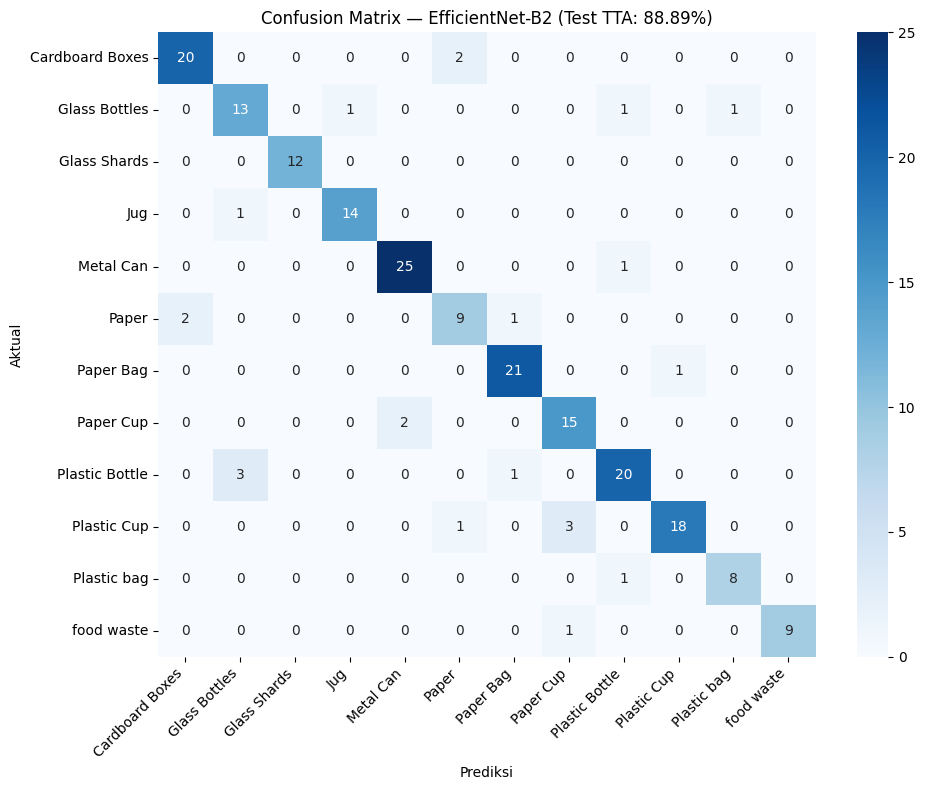

In [7]:
def evaluate_test_with_tta(model, loader):
    model.eval()
    preds_std, preds_tta, all_labels = [], [], []
    times = []

    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)

            # 1. Prediksi Standar (1x forward pass)
            start = time.time()
            logits_orig = model(imgs)
            times.append((time.time() - start) / imgs.size(0))
            probs_orig = torch.softmax(logits_orig, dim=1)

            # 2. TTA: Asli + Horizontal Flip + Slight Center Zoom (90%)
            imgs_flip = torch.flip(imgs, dims=[3])
            probs_flip = torch.softmax(model(imgs_flip), dim=1)

            crop_size = int(IMG_SIZE * 0.9)
            imgs_zoom = TF.resize(TF.center_crop(imgs, [crop_size, crop_size]), [IMG_SIZE, IMG_SIZE])
            probs_zoom = torch.softmax(model(imgs_zoom), dim=1)

            probs_avg = (probs_orig + probs_flip + probs_zoom) / 3.0

            preds_std.extend(torch.argmax(probs_orig, dim=1).cpu().numpy())
            preds_tta.extend(torch.argmax(probs_avg, dim=1).cpu().numpy())
            all_labels.extend(labels.numpy())

    acc_std = accuracy_score(all_labels, preds_std)
    acc_tta = accuracy_score(all_labels, preds_tta)
    avg_ms = np.mean(times) * 1000
    return acc_std, acc_tta, avg_ms, all_labels, preds_tta

print("=== Ringkasan Perbandingan Arsitektur v3 (Valid Acc vs Test Acc vs Test Acc TTA) ===")
print(f"{'Model':18s} | {'Valid Acc':10s} | {'Test Std':10s} | {'Test TTA':10s} | {'Ukuran':9s} | {'Latency'}")
print("-" * 82)

best_name = None
best_test_tta = -1.0
best_eval_pack = None

for nama, res in hasil_perbandingan.items():
    acc_std, acc_tta, avg_ms, y_true, y_pred_tta = evaluate_test_with_tta(res["model"], test_loader)
    size_mb = os.path.getsize(res["path"]) / (1024 * 1024)
    print(f"{nama:18s} | {res['best_val']*100:8.2f}%  | {acc_std*100:8.2f}%  | {acc_tta*100:8.2f}%  | {size_mb:6.2f} MB | {avg_ms:.2f} ms")
    if acc_tta > best_test_tta:
        best_test_tta = acc_tta
        best_name = nama
        best_eval_pack = (y_true, y_pred_tta)

print(f"\nModel Terbaik (berdasarkan Test Accuracy TTA): {best_name} ({best_test_tta*100:.2f}%)")
best_model = hasil_perbandingan[best_name]["model"]

y_true, y_pred = best_eval_pack
print("\n=== Classification Report (Test Set + TTA) ===")
print(classification_report(y_true, y_pred, target_names=train_ds.classes))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=train_ds.classes, yticklabels=train_ds.classes, cmap='Blues')
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title(f"Confusion Matrix — {best_name} (Test TTA: {best_test_tta*100:.2f}%)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 7. Export Model Terbaik ke 1 File ONNX Utuh (`dynamo=False`) & Verifikasi

In [8]:
import onnxruntime as ort
from google.colab import files

best_model.eval()
dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)
nama_file_onnx = "klasifikasi-sampah-v3.onnx"

torch.onnx.export(
    best_model, dummy_input, nama_file_onnx,
    export_params=True,
    opset_version=14,
    do_constant_folding=True,
    input_names=["input"], output_names=["output"],
    dynamic_axes={"input": {0: "batch_size"}, "output": {0: "batch_size"}},
    dynamo=False
)

# Verifikasi langsung dengan ONNX Runtime
size_onnx_mb = os.path.getsize(nama_file_onnx) / (1024 * 1024)
sess = ort.InferenceSession(nama_file_onnx)
test_out = sess.run(None, {"input": np.random.randn(1, 3, IMG_SIZE, IMG_SIZE).astype(np.float32)})[0]
print(f"✅ Export sukses! {nama_file_onnx} ({size_onnx_mb:.2f} MB) | Output shape: {test_out.shape}")

with open("labels.txt", "w") as f:
    f.write("\n".join(train_ds.classes))

files.download(nama_file_onnx)
files.download("labels.txt")

You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html


✅ Export sukses! klasifikasi-sampah-v3.onnx (29.41 MB) | Output shape: (1, 12)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>